# Método de Neville
## Interpolación polinomial (Algoritmo 3.1, Burden)

**Curso:** Métodos Numéricos  
**Nombre:** GOMEZ AGUIRRE ROCIO

###  ¿De qué trata este código?

Si conocemos varios puntos $(x_0, f(x_0)), \dots, (x_n, f(x_n))$ y queremos estimar el valor de $f$ en un número $x$ que no está en la tabla, podemos usar un polinomio de interpolación.

El **método de Neville** calcula ese valor **sin escribir el polinomio**, sino llenando una tabla $Q$ paso a paso:

$$Q_{i,0} = f(x_i)$$

$$Q_{i,j} = \frac{(x - x_{i-j})\,Q_{i,j-1} - (x - x_i)\,Q_{i-1,j-1}}{x_i - x_{i-j}}$$

El resultado final (la aproximación de $f(x)$ con todos los puntos) queda en la esquina $Q_{n,n}$.

**Lo que hace el cuaderno:**
1. Implementa el Algoritmo 3.1 en una función.
2. La prueba con el ejemplo 2 de Burden.
3. Muestra la tabla $Q$ y una gráfica de cómo mejora la aproximación al subir el grado.

In [13]:
# matplotlib sirve para hacer las gráficas
import matplotlib.pyplot as plt

##  Algoritmo 3.1: método de Neville

La función recibe:
- `x_datos`: lista con los nodos $x_0, \dots, x_n$
- `y_datos`: lista con los valores $f(x_0), \dots, f(x_n)$
- `x`: el punto donde queremos aproximar

y regresa la tabla `Q` completa.

In [14]:
def neville(x_datos, y_datos, x):
    n = len(x_datos)

    # primero hago una tabla de n x n con ceros
    Q = []
    for i in range(n):
        fila = []
        for j in range(n):
            fila.append(0)
        Q.append(fila)

    # la primera columna es f(x_i)
    for i in range(n):
        Q[i][0] = y_datos[i]

    # se llenan las otras columnas con la fórmula de Neville
    for i in range(1, n):
        for j in range(1, i + 1):
            arriba = (x - x_datos[i-j]) * Q[i][j-1]
            abajo = (x - x_datos[i]) * Q[i-1][j-1]
            Q[i][j] = (arriba - abajo) / (x_datos[i] - x_datos[i-j])

    return Q

## Prueba: ejemplo 2 (página 89, Burden)

Datos de la tabla 3.5 (valores de $f$ en $x = 1.0, 1.3, 1.6, 1.9, 2.2$). Queremos aproximar $f(1.5)$ y comparar con la tabla 3.6 del libro:

In [15]:
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
x_buscado = 1.5

Q = neville(x_datos, y_datos, x_buscado)

# imprimo la tabla Q
print("Tabla Q del método de Neville (x = " + str(x_buscado) + "):")
print()
for i in range(len(x_datos)):
    renglon = str(x_datos[i]) + "   "
    for j in range(i + 1):
        renglon = renglon + format(Q[i][j], ".7f") + "   "
    print(renglon)

Tabla Q del método de Neville (x = 1.5):

1.0   0.7651977   
1.3   0.6200860   0.5233449   
1.6   0.4554022   0.5102968   0.5124715   
1.9   0.2818186   0.5132634   0.5112857   0.5118127   
2.2   0.1103623   0.5104270   0.5137361   0.5118302   0.5118200   


### Agregando un sexto nodo

El libro dice que, si $Q_{4,4}$ no es suficientemente precisa, se puede agregar otro nodo. Aquí se agrega $x_5 = 2.5$, con $f(2.5) = -0.0483838$ (función de Bessel de orden cero), y se agrega una fila a la tabla.

In [16]:
# agrego el nodo x5 = 2.5 a las listas
x_extra = x_datos + [2.5]
y_extra = y_datos + [-0.0483838]

Q_extra = neville(x_extra, y_extra, x_buscado)

# solo imprimo la fila nueva (la fila 5)
print("Fila nueva de la tabla:")
renglon = str(x_extra[5]) + "   "
for j in range(6):
    renglon = renglon + format(Q_extra[5][j], ".7f") + "   "
print(renglon)

Fila nueva de la tabla:
2.5   -0.0483838   0.4807699   0.5301984   0.5119070   0.5118430   0.5118277   


##  Gráfica de las aproximaciones

Cada $Q_{i,i}$ es la aproximación usando polinomios de grado $i$. La línea punteada es el valor real de $f(1.5)$ (Q(5,5) del libro).

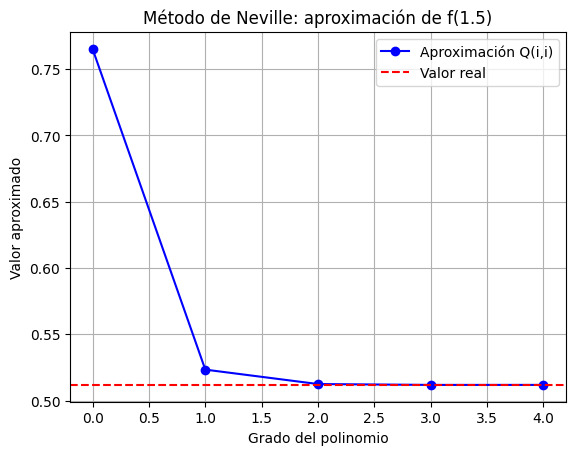

In [17]:
# tomo la diagonal de la tabla (las mejores aproximaciones de cada grado)
grados = []
aproximaciones = []
for i in range(len(x_datos)):
    grados.append(i)
    aproximaciones.append(Q[i][i])

valor_real = Q_extra[5][5]   # Q(5,5) del libro: 0.5118277, correcto a 7 decimales

plt.plot(grados, aproximaciones, "o-", color="blue", label="Aproximación Q(i,i)")
plt.axhline(valor_real, color="red", linestyle="--", label="Valor real")
plt.title("Método de Neville: aproximación de f(1.5)")
plt.xlabel("Grado del polinomio")
plt.ylabel("Valor aproximado")
plt.legend()
plt.grid(True)
plt.show()

## Solución final

In [18]:
resultado = Q[len(x_datos) - 1][len(x_datos) - 1]
error = abs(valor_real - resultado)

print("=" * 45)
print("SOLUCIÓN FINAL")
print("=" * 45)
print("f(" + str(x_buscado) + ") ≈ Q(4,4) =", format(resultado, ".7f"))
print("Q(5,5) con x5 = 2.5 =", format(valor_real, ".7f"))
print("Diferencia Q(4,4)-Q(5,5) =", format(error, ".2e"))
print("=" * 45)

SOLUCIÓN FINAL
f(1.5) ≈ Q(4,4) = 0.5118200
Q(5,5) con x5 = 2.5 = 0.5118277
Diferencia Q(4,4)-Q(5,5) = 7.67e-06


## Conclusión

Con el método de Neville se aproximó $f(1.5)$ usando los 5 puntos de la tabla. Al aumentar el grado, la aproximación se acerca al valor real. Lo bueno de este método es que no hace falta construir el polinomio, solo llenar la tabla $Q$.